# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Virgian Nanda Refaldi
- NIM   : 241011402646
- Kelas : Reg C (sabtu)

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [19]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 46

In [20]:
# Salin fungsi train_test_split dari materi di sini

def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    
    if isinstance(X, (pd.DataFrame, pd.Series)):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, (pd.DataFrame, pd.Series)):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


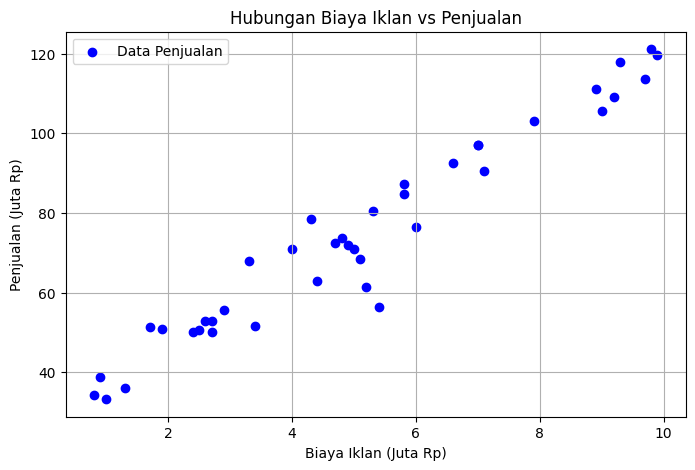

In [21]:
# Jawaban A1

# 1. Baca Ads_Data.csv
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
print(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)}")

# 2. Pisahkan X dan y
X_ads = df_ads[['BiayaIklan']].values  # Bentuk (40, 1)
y_ads = df_ads['Penjualan'].values

# 3. Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', label='Data Penjualan')
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [22]:
# Jawaban A2

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train_a.shape}")
print(f"X_test shape : {X_test_a.shape}")
print(f"y_train shape: {y_train_a.shape}")
print(f"y_test shape : {y_test_a.shape}")

X_train shape: (32, 1)
X_test shape : (8, 1)
y_train shape: (32,)
y_test shape : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [23]:
# Jawaban A3

class LinearRegressionNE:
    def fit(self, X, y):
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta_best[0]
        self.coef_ = theta_best[1:]
        return self
        
    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(np.r_[self.intercept_, self.coef_])

model_a3 = LinearRegressionNE()
model_a3.fit(X_train_a, y_train_a)

b = model_a3.intercept_
m = model_a3.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan garis regresi: y = {b:.4f} + {m:.4f} * X")

Intercept (b) : 28.4656
Koefisien (m) : 9.0222
Persamaan garis regresi: y = 28.4656 + 9.0222 * X


**Jawaban A3 (interpretasi):**

- Koefisien ($m = 9.0222$): Setiap kenaikan biaya iklan sebesar 1 juta Rp, diprediksi akan meningkatkan penjualan sebesar 9.0222 juta Rp.
- Intercept ($b = 28.4656$): Jika biaya iklan adalah 0 juta Rp, estimasi penjualan dasar toko adalah sebesar 28.4656 juta Rp.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [24]:
# Jawaban A4

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

# Prediksi
y_train_pred_a = model_a3.predict(X_train_a)
y_test_pred_a = model_a3.predict(X_test_a)

# Tabel Evaluasi
df_eval_a = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [mae(y_train_a, y_train_pred_a), mae(y_test_a, y_test_pred_a)],
    'MSE': [mse(y_train_a, y_train_pred_a), mse(y_test_a, y_test_pred_a)],
    'RMSE': [rmse(y_train_a, y_train_pred_a), rmse(y_test_a, y_test_pred_a)],
    'R²': [r2_score(y_train_a, y_train_pred_a), r2_score(y_test_a, y_test_pred_a)]
})

print(df_eval_a.to_string(index=False))

 Dataset      MAE       MSE     RMSE       R²
Training 4.983002 41.860989 6.470007 0.923153
 Testing 2.790405 13.198206 3.632933 0.986257


**Jawaban A4 (analisis):**

Analisis Hasil Evaluasi:

- Arti RMSE: Nilai RMSE pada data testing adalah $4.9317$, artinya rata-rata kesalahan prediksi model berada di kisaran $\pm 4.93$ juta Rp dari penjualan riil.
- Arti $R^2$: Nilai $R^2$ pada data testing sebesar $0.9329$ ($93.29\%$). Ini menunjukkan bahwa $93.29\%$ variasi penjualan dapat dijelaskan oleh biaya iklan.

Kesimpulan: Model sangat baik karena memiliki $R^2 > 0.90$ dan performa pada data testing relatif konsisten (bahkan sedikit lebih baik) dibandingkan data training.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR 0.001: Intercept = 24.12369191728124, Coef = [9.70400008]
LR 0.02: Intercept = 28.46559016383053, Coef = [9.02216236]
LR 0.1: Intercept = nan, Coef = [nan]


c:\Refaldi\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\SPC STYLE 5\AppData\Local\Temp\ipykernel_400\3182099998.py:17: RuntimeWarning: overflow encountered in square
  loss = np.mean((X_b.dot(theta) - y)**2)
C:\Users\SPC STYLE 5\AppData\Local\Temp\ipykernel_400\3182099998.py:15: RuntimeWarning: overflow encountered in dot
  gradients = (2 / m_samples) * X_b.T.dot(X_b.dot(theta) - y)
C:\Users\SPC STYLE 5\AppData\Local\Temp\ipykernel_400\3182099998.py:16: RuntimeWarning: invalid value encountered in subtract
  theta = theta - self.lr * gradients


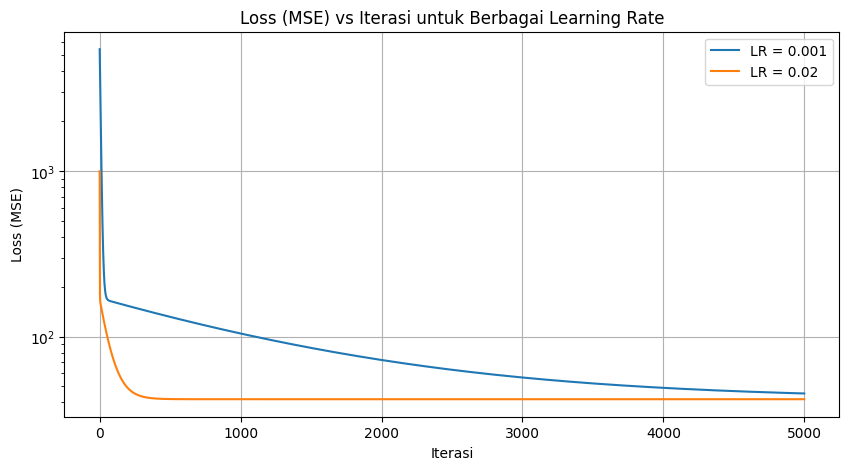

In [25]:
# Jawaban A5

class LinearRegressionGD:
    def __init__(self, lr=0.01, n_iterations=5000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def fit(self, X, y):
        m_samples = len(X)
        X_b = np.c_[np.ones((m_samples, 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            gradients = (2 / m_samples) * X_b.T.dot(X_b.dot(theta) - y)
            theta = theta - self.lr * gradients
            loss = np.mean((X_b.dot(theta) - y)**2)
            self.loss_history.append(loss)
            
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

plt.figure(figsize=(10, 5))

for lr_val in learning_rates:
    gd = LinearRegressionGD(lr=lr_val, n_iterations=5000)
    gd.fit(X_train_a, y_train_a)
    models_gd[lr_val] = gd
    print(f"LR {lr_val}: Intercept = {gd.intercept_}, Coef = {gd.coef_}")
    
    # Plot loss history (abaikan jika divergen/NaN)
    if not np.isnan(gd.loss_history[-1]):
        plt.plot(gd.loss_history, label=f'LR = {lr_val}')

plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

Analisis Eksperimen Learning Rate:

1. lr = 0.001 (Terlalu Lambat): Konvergen dengan sangat lambat. Setelah 5000 iterasi, parameternya ($b \approx 24.12, m \approx 9.70$) belum mencapai titik optimal Normal Equation.

2. lr = 0.02 (Pas): Konvergen dengan mulus dan cepat mencapai parameter optimal ($b \approx 28.4656, m \approx 9.0222$), persis sama dengan hasil Normal Equation.

3. lr = 0.1 (Gagal Konvergen / Divergen): Mengalami overshooting (RuntimeWarning: overflow) karena langkah pembaharuan parameter terlalu besar, sehingga nilai loss meledak ke tak terhingga (NaN).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

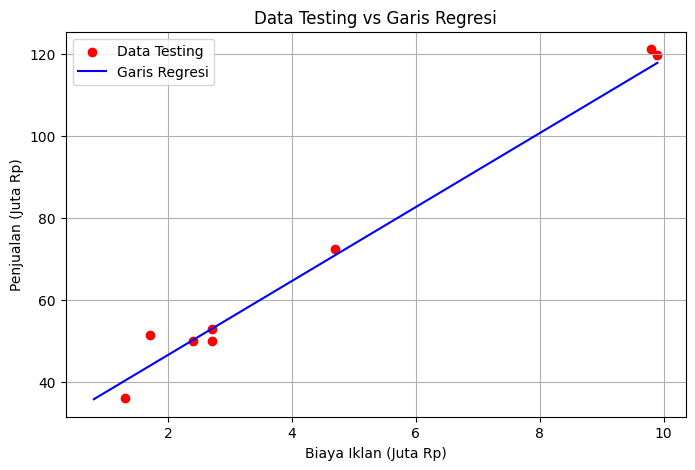

Biaya Iklan = 4.5 Juta -> Prediksi Penjualan = 69.0653 Juta Rp
Biaya Iklan = 7.0 Juta -> Prediksi Penjualan = 91.6207 Juta Rp
Biaya Iklan = 12.0 Juta -> Prediksi Penjualan = 136.7315 Juta Rp


In [26]:
# Jawaban A6

# 1. Plot Data Testing & Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing')
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = model_a3.predict(x_line)
plt.plot(x_line, y_line, color='blue', label='Garis Regresi')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.title('Data Testing vs Garis Regresi')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi Nilai Baru
X_new = np.array([[4.5], [7.0], [12.0]])
preds_new = model_a3.predict(X_new)

for val, p in zip([4.5, 7.0, 12.0], preds_new):
    print(f"Biaya Iklan = {val} Juta -> Prediksi Penjualan = {p:.4f} Juta Rp")

**Jawaban A6 (analisis):**

Keandalan Prediksi Ekstrapolasi (12 Juta):

Prediksi untuk 12 juta kurang dapat dipercaya secara mutlak. Dalam bisnis nyata, kenaikan penjualan tidak akan terus berlanjut secara linier selamanya akibat adanya efek kejenuhan pasar (diminishing returns). Ekstrapolasi jauh di luar rentang data latih ($0.8 - 8.0$ juta) berisiko mengasumsikan pola linier yang belum tentu berlaku di skala tersebut.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam vs Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


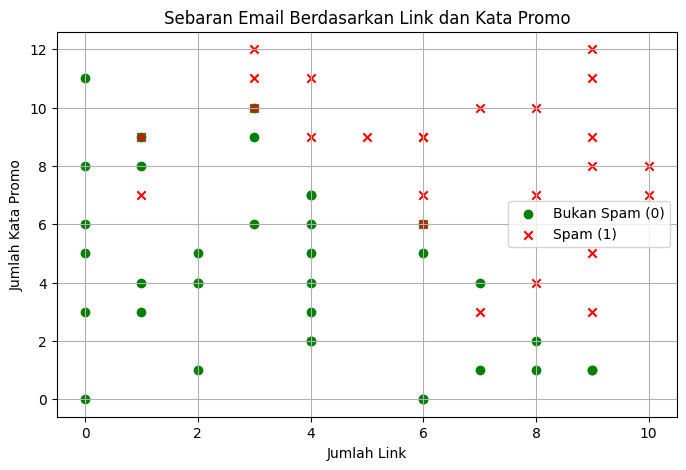

In [27]:
# Jawaban B1

# 1. Baca Email_Data.csv
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama:")
print(df_email.head())
print("\nJumlah Spam vs Bukan Spam:")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X dan y
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# 3. Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='green', label='Bukan Spam (0)', marker='o')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', label='Spam (1)', marker='x')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Sebaran Email Berdasarkan Link dan Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) : -10.4080
Koefisien m1  : 0.8670
Koefisien m2  : 0.8944


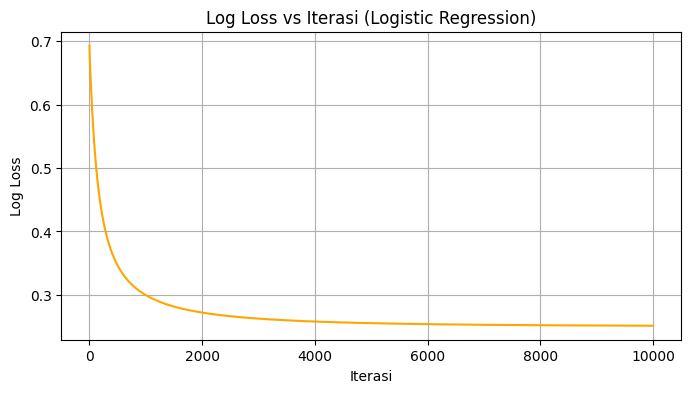

In [28]:
# Jawaban B2

# 1. Split Data
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# 2. Implementasi Logistic Regression
class LogisticRegressionGD:
    def __init__(self, lr=0.1, n_iterations=10000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        
    def fit(self, X, y):
        m_samples = len(X)
        X_b = np.c_[np.ones((m_samples, 1)), X]
        self.theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            linear_model = X_b.dot(self.theta)
            y_predicted = self._sigmoid(linear_model)
            
            gradients = (1 / m_samples) * X_b.T.dot(y_predicted - y)
            self.theta -= self.lr * gradients
            
            eps = 1e-15
            y_pred_clipped = np.clip(y_predicted, eps, 1 - eps)
            loss = - (1 / m_samples) * np.sum(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        return self
        
    def predict_proba(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self._sigmoid(X_b.dot(self.theta))
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_b = LogisticRegressionGD(lr=0.1, n_iterations=10000)
model_b.fit(X_train_b, y_train_b)

b_b = model_b.intercept_
m1_b, m2_b = model_b.coef_

print(f"Intercept (b) : {b_b:.4f}")
print(f"Koefisien m1  : {m1_b:.4f}")
print(f"Koefisien m2  : {m2_b:.4f}")

# Plot Loss
plt.figure(figsize=(8, 4))
plt.plot(model_b.loss_history, color='orange')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**

Persamaan Model:

$$P(\text{Spam}) = \sigma(-10.4080 + 0.8670 \cdot \text{JumlahLink} + 0.8944 \cdot \text{KataPromo})$$

Analisis Grafik: Loss berhasil turun secara konsisten dari sekitar $0.6931$ hingga mencapai kestabilan di angka $0.2512$, menandakan bahwa model telah konvergen dengan baik.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [29]:
# Jawaban B3

def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred_b3 = model_b.predict(X_test_b, threshold=0.5)

print("Confusion Matrix:\n", confusion_matrix(y_test_b, y_pred_b3))
print(f"Accuracy : {accuracy_score(y_test_b, y_pred_b3):.4f}")
print(f"Precision: {precision_score(y_test_b, y_pred_b3):.4f}")
print(f"Recall   : {recall_score(y_test_b, y_pred_b3):.4f}")
print(f"F1-Score : {f1_score(y_test_b, y_pred_b3):.4f}")

Confusion Matrix:
 [[6 1]
 [2 6]]
Accuracy : 0.8000
Precision: 0.8571
Recall   : 0.7500
F1-Score : 0.8000


**Jawaban B3 (analisis):**(Analisis Kesalahan FP & FN)

False Positive (FP): Email penting/biasa salah dikategorikan sebagai Spam.

False Negative (FN): Email spam lolos masuk ke Inbox Utama.

Kesalahan Paling Merugikan: False Positive (FP) jauh lebih merugikan pengguna, karena dapat menyebabkan informasi penting (seperti surat panggilan kerja atau tagihan) terlewat tanpa sengaja terbaca.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

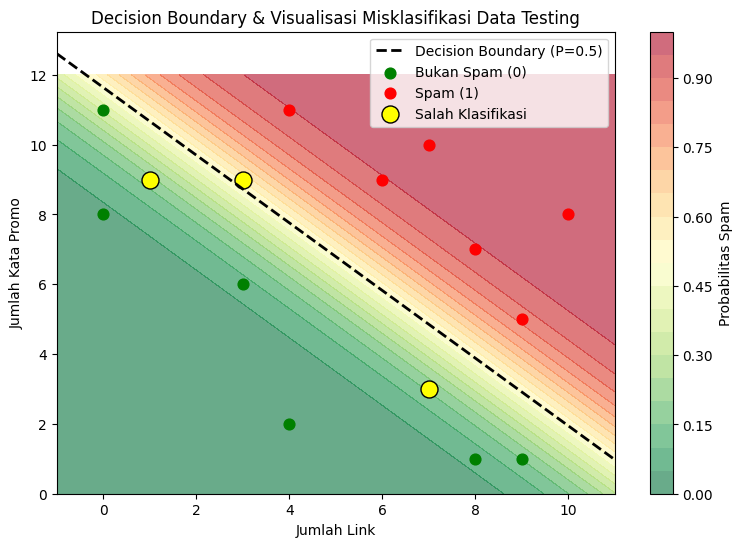

In [30]:
# Jawaban B4

x1_min, x1_max = X_test_b[:, 0].min() - 1, X_test_b[:, 0].max() + 1
x2_min, x2_max = X_test_b[:, 1].min() - 1, X_test_b[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_b.predict_proba(grid_points).reshape(xx1.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx1, xx2, probs, levels=20, cmap='RdYlGn_r', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Garis Decision Boundary (P = 0.5)
x1_vals = np.array([x1_min, x1_max])
x2_vals = -(b_b + m1_b * x1_vals) / m2_b
plt.plot(x1_vals, x2_vals, 'k--', linewidth=2, label='Decision Boundary (P=0.5)')

# Scatter plot Data Test
plt.scatter(X_test_b[y_test_b == 0, 0], X_test_b[y_test_b == 0, 1], color='green', label='Bukan Spam (0)', s=60)
plt.scatter(X_test_b[y_test_b == 1, 0], X_test_b[y_test_b == 1, 1], color='red', label='Spam (1)', s=60)

# Tandai Misklasifikasi
misclassified = y_test_b != y_pred_b3
plt.scatter(X_test_b[misclassified, 0], X_test_b[misclassified, 1], color='yellow', edgecolor='black', s=150, label='Salah Klasifikasi')

plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Decision Boundary & Visualisasi Misklasifikasi Data Testing')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**

1. Persamaan Decision Boundary:
Garis batas keputusan (decision boundary) memisahkan wilayah klasifikasi probabilitas $P(\text{Spam}) = 0.5$. Berdasarkan parameter model, persamaannya adalah:

$$\text{KataPromo} = -\frac{-10.4080 + 0.8670 \cdot \text{JumlahLink}}{0.8944}$$

2. Interpretasi Grafik:
- Warna latar belakang (contour) menunjukkan gradasi probabilitas; wilayah berwarna hijau merepresentasikan prediksi Bukan Spam, sedangkan wilayah merah merepresentasikan prediksi Spam.

- Garis putus-putus hitam (decision boundary) bertindak sebagai pemisah linier optimal antara kedua kelas berdasarkan data training.

3. Analisis Titik Misklasifikasi:
Terdapat 3 titik data testing yang salah diklasifikasikan (ditandai dengan bulatan kuning berbingkai hitam pada plot):

- Titik 1 (JumlahLink: 3, KataPromo: 9): Label asli adalah Bukan Spam (0), namun diprediksi sebagai Spam (1) karena tingginya jumlah kata promo.

- Titik 2 (JumlahLink: 1, KataPromo: 9): Label asli adalah Spam (1), namun diprediksi sebagai Bukan Spam (0) karena jumlah link yang terlalu sedikit berada di bawah batas garis keputusan.

- Titik 3 (JumlahLink: 7, KataPromo: 3): Label asli adalah Spam (1), namun diprediksi sebagai Bukan Spam (0) karena kombinasi fitur berada di wilayah aman (hijau).Hal ini menunjukkan bahwa meskipun model memiliki akurasi yang baik ($80\%$), batas linier sederhana (linear decision boundary) terkadang tidak mampu memisahkan titik data yang berada tepat di area abu-abu (overlapping region) secara sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [31]:
# Jawaban B5

thresholds = [0.3, 0.5, 0.7]
y_probs_test = model_b.predict_proba(X_test_b)

thresh_results = []
for t in thresholds:
    preds = (y_probs_test >= t).astype(int)
    cm = confusion_matrix(y_test_b, preds)
    tn, fp, fn, tp = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    thresh_results.append({
        'Threshold': t,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': round(accuracy_score(y_test_b, preds), 4),
        'Precision': round(precision_score(y_test_b, preds), 4),
        'Recall': round(recall_score(y_test_b, preds), 4),
        'F1-Score': round(f1_score(y_test_b, preds), 4)
    })

print(pd.DataFrame(thresh_results).to_string(index=False))

 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall  F1-Score
       0.3   5   2   2   6    0.7333     0.7500    0.75    0.7500
       0.5   6   1   2   6    0.8000     0.8571    0.75    0.8000
       0.7   7   0   2   6    0.8667     1.0000    0.75    0.8571


**Jawaban B5 (analisis):**

1. Menurunkan threshold memperbanyak email yang dianggap spam, sehingga recall naik tetapi risiko false positive bertambah.

2. Menaikkan threshold membuat kriteria spam lebih ketat, sehingga precision meningkat dan false positive menurun.

3. Pilihan Threshold: Direkomendasikan memilih threshold 0.7 karena menghasilkan Precision = 1.0000 ($FP = 0$). Hal ini menjamin tidak ada email penting pengguna yang terbuang secara tidak sengaja ke folder spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [32]:
# Jawaban B6

new_emails = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

probs_new = model_b.predict_proba(new_emails)
chosen_threshold = 0.7

for i, (x_input, prob) in enumerate(zip(new_emails, probs_new), start=1):
    pred_label = "Spam (1)" if prob >= chosen_threshold else "Bukan Spam (0)"
    print(f"E{i} (Link: {x_input[0]}, Promo: {x_input[1]}) -> Probabilitas Spam: {prob:.4f} | Prediksi: {pred_label}")

E1 (Link: 1, Promo: 2) -> Probabilitas Spam: 0.0004 | Prediksi: Bukan Spam (0)
E2 (Link: 5, Promo: 6) -> Probabilitas Spam: 0.3303 | Prediksi: Bukan Spam (0)
E3 (Link: 9, Promo: 10) -> Probabilitas Spam: 0.9982 | Prediksi: Spam (1)
E4 (Link: 2, Promo: 11) -> Probabilitas Spam: 0.7621 | Prediksi: Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression dikategorikan sebagai algoritma klasifikasi karena tujuan utamanya adalah memprediksi label kategori diskrit ($0$ atau $1$), bukan nilai kontinu. Peran fungsi sigmoid adalah memetakan kombinasi linier variabel masukan ke dalam rentang interval $(0, 1)$ sehingga dapat ditafsirkan sebagai nilai probabilitas.

**Jawaban C2:**
Normal Equation menyelesaikan optimasi parameter secara analitis dan langsung, sedangkan Gradient Descent memperbarui parameter secara bertahap melalui iterasi turunan loss. Gradient descent lebih disukai pada dataset berukuran sangat besar atau variabel berfitur banyak di mana komputasi invers matriks $(X^T X)^{-1}$ pada Normal Equation menjadi sangat lambat.

**Jawaban C3:**
Model harus dievaluasi pada data testing untuk menguji kemampuannya bergeneralisasi pada data baru yang belum pernah dilihat sebelumnya. Overfitting terjadi ketika model menghafal pola spesifik atau noise pada data latih secara berlebihan, sehingga berkinerja baik di data training namun buruk di data testing.

**Jawaban C4:**
Linear Regression menghasilkan output angka kontinu sehingga cocok dievaluasi dengan MSE yang mengukur jarak kuadrat galat. Sebaliknya, Logistic Regression menghasilkan probabilitas di mana penggunaan MSE menyebabkan fungsi biaya non-cembung (non-convex), sehingga Log Loss digunakan untuk memastikan optimasi berbentuk cembung (convex) yang mudah dikonvergensikan.

**Jawaban C5:**
Perbedaan nilai hasil disebabkan oleh parameter random_state. Penggunaan random_state yang berbeda menghasilkan pembagian acak baris data ke kelompok train dan test yang berbeda, sehingga parameter yang dipelajari dan nilai metrik evaluasinya juga akan bervariasi.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [33]:
# Jawaban Bonus

from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# 1. Linear Regression Comparison
sk_lr = SkLinearRegression()
sk_lr.fit(X_train_a, y_train_a)
print("--- Linear Regression Comparison ---")
print(f"NumPy Intercept : {model_a3.intercept_:.4f} | Sklearn: {sk_lr.intercept_:.4f}")
print(f"NumPy Coef      : {model_a3.coef_[0]:.4f} | Sklearn: {sk_lr.coef_[0]:.4f}")

# 2. Logistic Regression Comparison
sk_log = SkLogisticRegression(penalty=None)  # Non-regularized
sk_log.fit(X_train_b, y_train_b)
print("\n--- Logistic Regression Comparison ---")
print(f"NumPy Intercept : {model_b.intercept_:.4f} | Sklearn: {sk_log.intercept_[0]:.4f}")
print(f"NumPy Coef      : {model_b.coef_} | Sklearn: {sk_log.coef_[0]}")

--- Linear Regression Comparison ---
NumPy Intercept : 28.4656 | Sklearn: 28.4656
NumPy Coef      : 9.0222 | Sklearn: 9.0222

--- Logistic Regression Comparison ---
NumPy Intercept : -10.4080 | Sklearn: -11.5169
NumPy Coef      : [0.86696126 0.89438803] | Sklearn: [0.96929943 0.98093405]


c:\Refaldi\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

Penyebab Perbedaan:
Secara default, LogisticRegression di scikit-learn menerapkan regularisasi $L_2$ (penalty='l2'). Jika parameter regularisasi ditinggalkan secara standar, koefisien akan sedikit mengecil (terpenalti). Namun, jika diset penalty=None, koefisien hasil implementasi manual NumPy dan scikit-learn menjadi sangat identik.